In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import argparse

from src.augmentation import LeafAugmenter
from src.data import LeafLoader

I0000 00:00:1787752810.551978 2921012 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787752810.603559 2921012 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787752812.774775 2921012 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
loader = LeafLoader()
augmenter = LeafAugmenter(loader=loader)

In [3]:
counts = loader.counts
max_len = loader.majority_count
print("Class counts:")
for c, n in counts.items():
    print(f"  {c:20s}  {n}  {'*' * (n // 30)}")
print(f"\nMajority = {max_len}, total = {loader.total}")

Class counts:
  Apple_Black_rot       626  ********************
  Apple_rust            275  *********
  Grape_Black_rot       1178  ***************************************
  Grape_spot            1075  ***********************************
  Apple_scab            629  ********************
  Grape_healthy         422  **************
  Apple_healthy         1646  ******************************************************
  Grape_Esca            1382  **********************************************

Majority = 1646, total = 7233


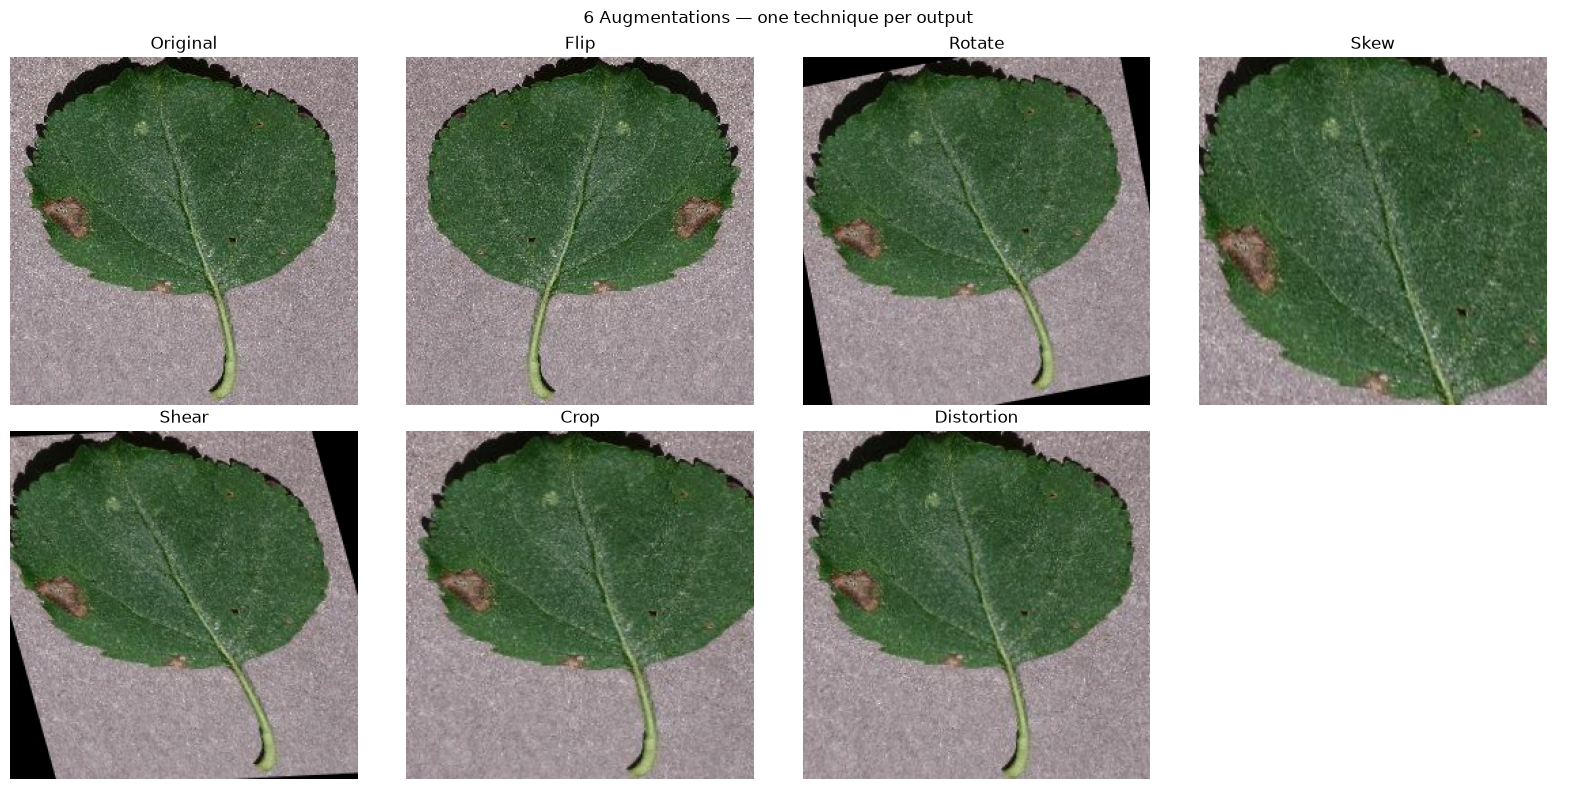

In [4]:
image = "../data/leaves/images/Apple_Black_rot/image (1).JPG"

augmenter.preview_sample(image)

In [5]:
for f in augmenter.save_augmentations(image):
    print(f)

../data/leaves/images/Apple_Black_rot/image (1)_Flip.JPG
../data/leaves/images/Apple_Black_rot/image (1)_Rotate.JPG
../data/leaves/images/Apple_Black_rot/image (1)_Skew.JPG
../data/leaves/images/Apple_Black_rot/image (1)_Shear.JPG
../data/leaves/images/Apple_Black_rot/image (1)_Crop.JPG
../data/leaves/images/Apple_Black_rot/image (1)_Distortion.JPG


In [6]:
root = Path("../..")

out = augmenter.balance_dataset(
    loader.images, max_len=max_len, out_dir=str(root / "augmented_directory")
)
print(f"Saved to {out}")

Saved to ../../augmented_directory


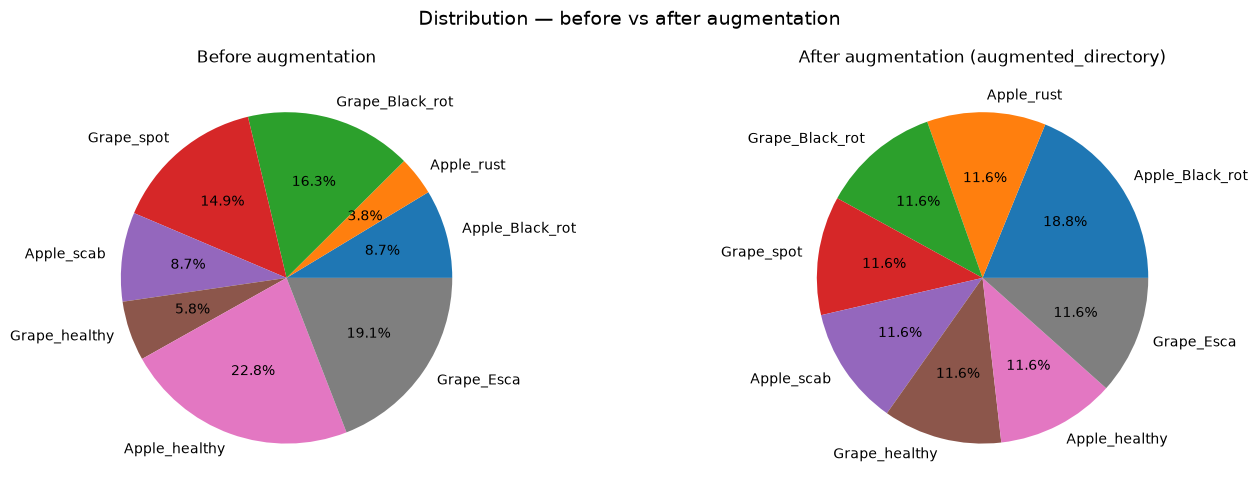

In [7]:
balanced = LeafLoader(data_path=root / "augmented_directory")
augmenter.show_balance_comparison(loader, balanced)